# Formative 2: Modeling Human Activity States Using Hidden Markov Models

**Author:** Ivan Manzi Ya Musana  |  **Assignment type:** individual (one student, one iPhone 13, one device id)

**Goal.** Recognize four human activity states, **standing, walking, jumping, still**, from smartphone
accelerometer and gyroscope signals with a Hidden Markov Model (HMM) that I implement from scratch in numpy
(forward-backward, Baum-Welch with a convergence check, Viterbi).

**Pipeline.** raw zips in `Data/` &rarr; `scripts/make_clean_dataset.py` &rarr; `Data_clean/{train,test}` &rarr;
2 s windows &rarr; 44 time/frequency features &rarr; z-score (train statistics only) &rarr; Gaussian-emission HMM
&rarr; Viterbi decoding of **unseen** test recordings.

**Honesty notes (read first).**
* Every number in this notebook is produced by the cells below; the report copies them from `results/`.
* Accelerometer / gyroscope **units are not stated in the files**. I label them m/s&sup2; and rad/s with an asterisk
  (inferred from the signal scale, **UNVERIFIED**).
* After the cleaning rules (1.5 s trimmed from each end, clips &lt; 5 s dropped) each activity has **less than 90 s** of
  usable data. The shortfall is documented in `Data_clean/build_log.txt` and in the report.

## 1. Setup and data loading (relative paths only)

In [1]:
import json, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
ROOT = Path.cwd()
if not (ROOT / "Data_clean").exists():          # allow running from a sub-folder
    ROOT = ROOT.parent
assert (ROOT / "Data_clean").exists(), "Data_clean/ not found - run: python scripts/make_clean_dataset.py"
DATA, FIG, RES = ROOT / "Data_clean", ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

ACTIVITIES = ["standing", "walking", "jumping", "still"]      # HMM hidden states Z (state k <-> activity k)
K = len(ACTIVITIES)
LABEL = {a: i for i, a in enumerate(ACTIVITIES)}
COLORS = {"standing": "#4C78A8", "walking": "#F58518", "jumping": "#E45756", "still": "#54A24B"}
SENSOR_COLS = ["ax", "ay", "az", "gx", "gy", "gz"]
WIN, HOP = 200, 100                                           # 2 s window, 50 % overlap at ~100 Hz
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
print("numpy", np.__version__, "| pandas", pd.__version__, "| root:", ROOT.name)

numpy 2.5.4 | pandas 3.1.0 | root: Formative1_TechinuqueII


In [2]:
manifest = pd.read_csv(DATA / "manifest.csv")
excluded = pd.read_csv(DATA / "excluded.csv")
clips = []
for r in manifest.itertuples():
    df = pd.read_csv(DATA / r.split / r.new_name)
    assert list(df.columns) == ["timestamp"] + SENSOR_COLS and not df.isna().any().any()
    clips.append(dict(name=r.new_name, split=r.split, activity=r.activity, df=df, notes=str(r.notes)))

summary = manifest.pivot_table(index="activity", columns="split", values="duration_s",
                               aggfunc=["count", "sum"]).reindex(ACTIVITIES)
summary.columns = [f"{'files' if a == 'count' else 'seconds'} ({s})" for a, s in summary.columns]
summary["seconds (total)"] = summary["seconds (train)"] + summary["seconds (test)"]
display(summary.round(1))
print("clips:", len(clips), "| train:", sum(c["split"] == "train" for c in clips),
      "| test:", sum(c["split"] == "test" for c in clips))
print("\nExcluded from the cleaned set (originals untouched in Data/):")
display(excluded.assign(reason=excluded.reason.str.slice(0, 110)))

,files (test),files (train),seconds (test),seconds (train),seconds (total)
activity,,,,,
standing,2,8,15.6,48.4,64.0
walking,3,10,23.1,63.6,86.7
jumping,2,9,10.6,63.1,73.7
still,3,6,21.3,37.1,58.5


clips: 43 | train: 33 | test: 10

Excluded from the cleaned set (originals untouched in Data/):


,original_zip,activity,reason
0,Data/standing/2026-10-28_17-17-21.zip,standing,too short after trimming 1.5 s from each end (...
1,Data/standing/2026-10-28_17-17-30.zip,standing,too short after trimming 1.5 s from each end (...
2,Data/standing/standing_02-2026-10-28_17-23-27.zip,standing,"mislabeled: signal looks like walking, not sta..."
3,Data/jumping/2026-10-28_17-06-26.zip,jumping,too short after trimming 1.5 s from each end (...
4,Data/jumping/jumping_-2026-10-28_16-41-22.zip,jumping,too short after trimming 1.5 s from each end (...
5,Data/still/2026-10-28_17-14-00.zip,still,too short after trimming 1.5 s from each end (...
6,Data/still/2026-10-28_17-14-08.zip,still,too short after trimming 1.5 s from each end (...
7,Data/still/2026-10-28_17-14-16.zip,still,too short after trimming 1.5 s from each end (...
8,Data/still/2026-10-28_17-14-34.zip,still,too short after trimming 1.5 s from each end (...


## 2. Sample-data plots (one per activity)

Five seconds of accelerometer (left) and gyroscope (right) from the typical un-flagged training clip of each activity (accelerometer std closest to the activity median).
Amplitudes differ by orders of magnitude, so every panel has its own y-scale.
&#42;Units are inferred (m/s&sup2;, rad/s), not stated in the files - **UNVERIFIED**.

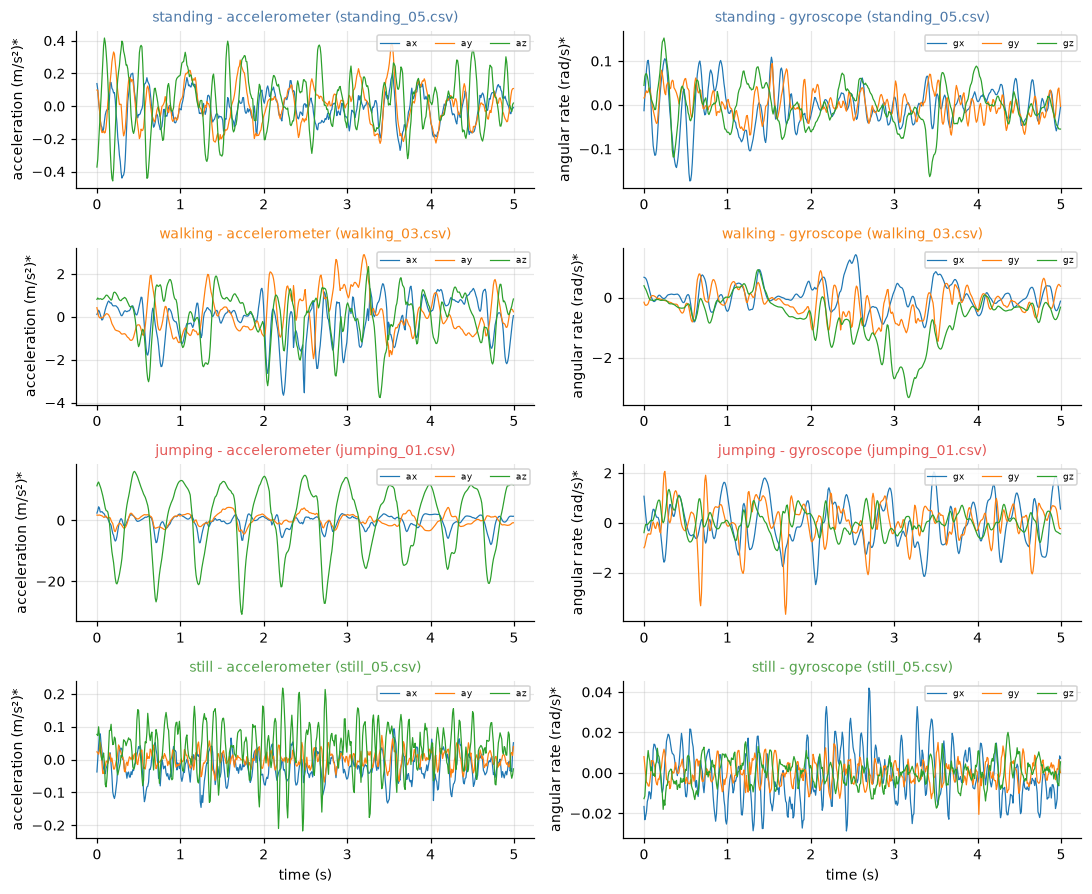

In [3]:
def accel_std(c):
    return np.sqrt((c["df"][["ax", "ay", "az"]] ** 2).sum(axis=1)).std()

def example_clip(act):
    '''Un-flagged training clip whose accelerometer-magnitude std is closest to the activity median.'''
    cands = [c for c in clips if c["activity"] == act and c["split"] == "train" and "QC:" not in c["notes"]]
    med = np.median([accel_std(c) for c in cands])
    return min(cands, key=lambda c: abs(np.log(accel_std(c)) - np.log(med)))

fig, axes = plt.subplots(4, 2, figsize=(10, 8.2))
for i, act in enumerate(ACTIVITIES):
    c = example_clip(act); seg = c["df"][c["df"].timestamp <= 5.0]
    for j, (cols, ylab) in enumerate([(["ax", "ay", "az"], "acceleration (m/s²)*"), (["gx", "gy", "gz"], "angular rate (rad/s)*")]):
        for col, ls in zip(cols, ["-", "-", "-"]):
            axes[i, j].plot(seg.timestamp, seg[col], lw=.8, label=col)
        axes[i, j].set_title(f"{act} - {'accelerometer' if j == 0 else 'gyroscope'} ({c['name']})", fontsize=9, color=COLORS[act])
        axes[i, j].set_ylabel(ylab); axes[i, j].legend(loc="upper right", ncol=3, fontsize=6, frameon=True, framealpha=.85, borderpad=.3)
        if i == 3: axes[i, j].set_xlabel("time (s)")
fig.tight_layout(); fig.savefig(FIG / "fig01_sample_signals.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Sampling-rate handling

All 52 recordings come from **one device (iPhone 13)** logged at the same nominal rate (`sampleRateMs = 10`, i.e.
100 Hz), so there is no cross-device rate mismatch to harmonize. I still **measure** the rate of every cleaned clip from
its timestamps instead of assuming it. Accelerometer and gyroscope were aligned by nearest timestamp
(`merge_asof`, 5 ms tolerance) in `scripts/make_clean_dataset.py`; this fixed the one 916-vs-917 row mismatch
(`2026-10-28_17-17-39`). If the measured rate is uniform, resampling is unnecessary and would only add interpolation
error.

nominal rate (metadata): 100 Hz | measured per clip: min 100.105, max 100.124, mean 100.118, std 0.0051 Hz
sample spacing over all 28,320 steps: min 9.98 ms, max 9.99 ms, mean 9.988 ms
-> rate is uniform (spread < 0.1 Hz, no gap > 11 ms): no resampling required. FS used for FFT bins = 100.118 Hz


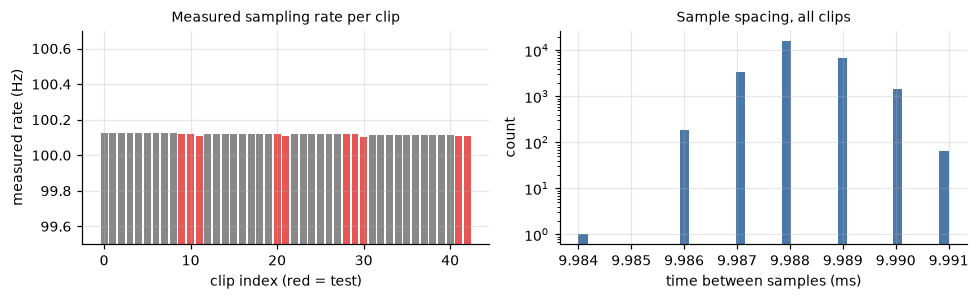

In [4]:
rows, all_dt = [], []
for c in clips:
    t = c["df"].timestamp.to_numpy(); dt = np.diff(t)
    all_dt.append(dt * 1e3)
    rows.append(dict(name=c["name"], split=c["split"], hz=(len(t) - 1) / (t[-1] - t[0]),
                     dt_min_ms=dt.min() * 1e3, dt_max_ms=dt.max() * 1e3))
hz_tab = pd.DataFrame(rows); all_dt = np.concatenate(all_dt)
FS = float(hz_tab.hz.mean())
print(f"nominal rate (metadata): 100 Hz | measured per clip: min {hz_tab.hz.min():.3f}, max {hz_tab.hz.max():.3f}, "
      f"mean {FS:.3f}, std {hz_tab.hz.std():.4f} Hz")
print(f"sample spacing over all {len(all_dt):,} steps: min {all_dt.min():.2f} ms, max {all_dt.max():.2f} ms, "
      f"mean {all_dt.mean():.3f} ms")
assert hz_tab.hz.max() - hz_tab.hz.min() < 0.1 and all_dt.max() < 11.0     # uniform -> no resampling needed
print("-> rate is uniform (spread < 0.1 Hz, no gap > 11 ms): no resampling required. FS used for FFT bins =", round(FS, 3), "Hz")

fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
ax[0].bar(range(len(hz_tab)), hz_tab.hz, color=["#888" if s == "train" else "#E45756" for s in hz_tab.split])
ax[0].set_ylim(99.5, 100.7); ax[0].set_xlabel("clip index (red = test)"); ax[0].set_ylabel("measured rate (Hz)")
ax[0].set_title("Measured sampling rate per clip", fontsize=9)
ax[1].hist(all_dt, bins=40, color="#4C78A8"); ax[1].set_yscale("log")
ax[1].set_xlabel("time between samples (ms)"); ax[1].set_ylabel("count"); ax[1].set_title("Sample spacing, all clips", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "fig02_sampling_rate.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Windowing

* **Window = 200 samples = 2 s at ~100 Hz, hop = 100 samples (50 % overlap).** The window length is tied to the measured
  rate (`WIN = 2 s x 100 Hz`).
* Why 2 s: at my measured walking cadence (~1.4-1.6 Hz) a window holds about 3 steps, so the walking rhythm is visible;
  a 2 s FFT has 0.5 Hz resolution, enough to separate walking (~1.5 Hz) from jumping (~2 Hz and its harmonics); and it is
  short enough that a window rarely spans two activities (activity changes are detected within ~1-2 s).
* 50 % overlap doubles the number of observations and smooths the sequence. Overlapping windows are correlated, so I
  split train/test **by file**, never by window.
* Each window inherits the label of its (single-activity) clip.

In [5]:
def make_windows(X, win=WIN, hop=HOP):
    n = (len(X) - win) // hop + 1
    return np.stack([X[i * hop:i * hop + win] for i in range(n)])

for c in clips:
    c["W"] = make_windows(c["df"][SENSOR_COLS].to_numpy())
    c["y"] = np.full(len(c["W"]), LABEL[c["activity"]])
wtab = pd.DataFrame([dict(activity=c["activity"], split=c["split"], windows=len(c["W"])) for c in clips])
display(wtab.pivot_table(index="activity", columns="split", values="windows", aggfunc="sum").reindex(ACTIVITIES))
print("window tensor example:", clips[0]["W"].shape, "(windows, samples, channels)")

split,test,train
activity,,
standing,13,37
walking,20,50
jumping,8,50
still,17,29


window tensor example: (4, 200, 6) (windows, samples, channels)


## 5. Feature extraction (44 features per window)

For **each sensor** (accelerometer, gyroscope) and window:

| Family | Features (per sensor) | Why it separates the activities |
|---|---|---|
| Time domain | **mean** x,y,z (3) | residual bias / posture drift; near 0 for the gravity-free accelerometer |
| | **std** x,y,z (3) | movement intensity: still &lt; standing &lt; walking &lt; jumping |
| | **RMS** x,y,z (3) | overall signal energy including any offset |
| | **SMA** (1) = mean(|x|+|y|+|z|) | classic whole-body activity-intensity measure |
| | **axis correlation** xy, xz, yz (3) | direction of motion: jumping is dominated by one axis, walking couples several axes |
| Frequency (FFT of the mean-removed, Hann-tapered window) | **dominant frequency** per axis (3), searched in 0.5-10 Hz | cadence: ~1.5 Hz walking, ~2 Hz jumping, noise-like for still/standing |
| | **spectral energy** per axis (3) | how much power sits in the motion band |
| | **spectral entropy** per axis (3) | periodic movement = low entropy; sensor noise / sway = high entropy |

The dominant frequency is computed **per axis**, not on the magnitude: rectifying the magnitude folds the spectrum
(a ~2 Hz jump shows up at ~4 Hz) and gave unstable values for walking in my audit.

In [6]:
SENSORS = {"acc": slice(0, 3), "gyro": slice(3, 6)}
PAIRS = [(0, 1, "xy"), (0, 2, "xz"), (1, 2, "yz")]

def extract_features(W):
    '''W: (n_windows, WIN, 6) -> (features (n_windows, 44), names). Needs the global measured rate FS.'''
    n, L, _ = W.shape
    f = np.fft.rfftfreq(L, d=1.0 / FS)
    band = (f >= 0.5) & (f <= 10.0)
    taper = np.hanning(L)
    cols, names = [], []
    def add(arr, base, axes="xyz"):
        arr = arr.reshape(n, -1)
        for i, a in enumerate(axes if arr.shape[1] > 1 else [""]):
            cols.append(arr[:, i]); names.append(f"{base}_{a}" if a else base)
    for s, sl in SENSORS.items():
        S = W[:, :, sl]
        mean, std = S.mean(1), S.std(1)
        Sc = S - mean[:, None, :]
        add(mean, f"{s}_mean")
        add(std, f"{s}_std")
        add(np.sqrt((S ** 2).mean(1)), f"{s}_rms")
        add(np.abs(S).sum(2).mean(1), f"{s}_sma")
        for i, j, lab in PAIRS:
            add((Sc[:, :, i] * Sc[:, :, j]).mean(1) / (std[:, i] * std[:, j] + 1e-12), f"{s}_corr_{lab}")
        P = np.abs(np.fft.rfft(Sc * taper[None, :, None], axis=1)) ** 2          # (n, bins, 3)
        add(f[band][np.argmax(P[:, band, :], axis=1)], f"{s}_domfreq")
        add(P[:, 1:, :].sum(1) / L, f"{s}_energy")
        p = P[:, 1:, :] / (P[:, 1:, :].sum(1, keepdims=True) + 1e-12)
        add(-(p * np.log(p + 1e-12)).sum(1) / np.log(p.shape[1]), f"{s}_entropy")
    return np.stack(cols, axis=1), names

for c in clips:
    c["F_raw"], FEATURE_NAMES = extract_features(c["W"])
D = len(FEATURE_NAMES)
print(D, "features per window:"); print(FEATURE_NAMES)
assert all(np.isfinite(c["F_raw"]).all() for c in clips)

44 features per window:
['acc_mean_x', 'acc_mean_y', 'acc_mean_z', 'acc_std_x', 'acc_std_y', 'acc_std_z', 'acc_rms_x', 'acc_rms_y', 'acc_rms_z', 'acc_sma', 'acc_corr_xy', 'acc_corr_xz', 'acc_corr_yz', 'acc_domfreq_x', 'acc_domfreq_y', 'acc_domfreq_z', 'acc_energy_x', 'acc_energy_y', 'acc_energy_z', 'acc_entropy_x', 'acc_entropy_y', 'acc_entropy_z', 'gyro_mean_x', 'gyro_mean_y', 'gyro_mean_z', 'gyro_std_x', 'gyro_std_y', 'gyro_std_z', 'gyro_rms_x', 'gyro_rms_y', 'gyro_rms_z', 'gyro_sma', 'gyro_corr_xy', 'gyro_corr_xz', 'gyro_corr_yz', 'gyro_domfreq_x', 'gyro_domfreq_y', 'gyro_domfreq_z', 'gyro_energy_x', 'gyro_energy_y', 'gyro_energy_z', 'gyro_entropy_x', 'gyro_entropy_y', 'gyro_entropy_z']


## 6. Normalization

1. **log10 of the strictly positive, heavy-tailed amplitude features** (std, RMS, SMA, spectral energy). They span
   about three orders of magnitude between still and jumping, so on a linear scale jumping would dominate and still/standing
   would collapse to the same value; a Gaussian also fits a log-scaled positive quantity better.
2. **Z-score with the mean and standard deviation of the TRAINING windows only**, then applied unchanged to the test
   windows (no test information leaks into the model). Features have different units and ranges (Hz, m/s&sup2;, rad/s,
   unit-free correlations), and the Gaussian emissions use one shared variance floor, so comparable scales are needed for the
   floor and for numerical conditioning.

Honest caveat: a Gaussian with its own variance per state is invariant to an affine rescaling, so z-scoring changes the
fit only through the variance floor and numerical conditioning; the log transform is the step that really reshapes the
distributions.

In [7]:
LOG_MASK = np.array([n.split("_")[1] in ("std", "rms", "sma", "energy") for n in FEATURE_NAMES])
print("log10-transformed features:", int(LOG_MASK.sum()), "of", D)

def log_scale(F):
    G = F.copy(); G[:, LOG_MASK] = np.log10(G[:, LOG_MASK] + 1e-12); return G

def fit_normalizer(F):
    mu, sd = F.mean(0), F.std(0)
    return mu, np.where(sd < 1e-9, 1.0, sd)

for c in clips:
    c["F"] = log_scale(c["F_raw"])
train_clips = [c for c in clips if c["split"] == "train"]
test_clips = [c for c in clips if c["split"] == "test"]
NORM = fit_normalizer(np.concatenate([c["F"] for c in train_clips]))
for c in clips:
    c["Z"] = (c["F"] - NORM[0]) / NORM[1]
Ztr = np.concatenate([c["Z"] for c in train_clips]); Zte = np.concatenate([c["Z"] for c in test_clips])
print(f"train z-scores: mean {Ztr.mean():+.3f}, std {Ztr.std():.3f} | test z-scores (not refit): "
      f"mean {Zte.mean():+.3f}, std {Zte.std():.3f}")

log10-transformed features: 20 of 44
train z-scores: mean +0.000, std 1.000 | test z-scores (not refit): mean -0.116, std 1.010


## 7. Hidden Markov Model from scratch (numpy)

* **Hidden states** Z = {standing, walking, jumping, still}; **observations** X = z-scored 44-dim window features.
* **Emissions** B: Gaussian with **diagonal covariance** and a variance floor (stops a state collapsing onto a few
  windows). **Transitions** A (4x4) and **initial distribution** pi.
* **Initialization from labeled training data** (class means/variances, empirical transitions and pi), then refinement
  with **Baum-Welch**, run in log-space, **stopping when the change in total log-likelihood is below epsilon** (a maximum
  iteration cap is only a safeguard).
* **Viterbi** (log-space) decodes the most likely state sequence.
* *Why these algorithms:* Baum-Welch (EM) *trains* the model without hand-set parameters; Viterbi *decodes* a window
  sequence into activity labels, which is exactly what the sensitivity / specificity / confusion-matrix evaluation scores.
* **Training sequences.** A transition between two activities never occurs *inside* one of my clips, so I concatenate
  whole training clips into long sequences in **seeded random order** (10 different shuffles, so the matrix is not just the
  recording order). **Initial distribution pi:** estimating pi from the start of only 10 random sequences is pure noise (in my first
run the still state received pi = 0.001 simply because no shuffle happened to begin with a still clip), so pi is instead
**fixed at its expectation: the share of training clips of each activity**, and Baum-Welch does not update it.
Consequence for interpretation: the **diagonal of A** reflects how persistent an activity is within a
  5-10 s clip, but the **off-diagonal entries are an artifact of the shuffling**, not measured human behavior.

In [8]:
def lse(a, axis):
    '''Numerically stable log-sum-exp along an axis.'''
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    return np.squeeze(m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)), axis=axis)

def log_emission(X, mu, var):
    '''Diagonal-Gaussian log density. X (T,D), mu/var (K,D) -> (T,K).'''
    d = X[:, None, :] - mu[None]
    return -0.5 * (np.log(2 * np.pi * var)[None] + d ** 2 / var[None]).sum(-1)

def forward(logB, logA, logpi):
    '''Log forward variables alpha (T,K) and sequence log-likelihood.'''
    T, Kk = logB.shape
    la = np.empty((T, Kk)); la[0] = logpi + logB[0]
    for t in range(1, T):
        la[t] = logB[t] + lse(la[t - 1][:, None] + logA, axis=0)
    return la, lse(la[-1], axis=0)

def backward(logB, logA):
    '''Log backward variables beta (T,K).'''
    T, Kk = logB.shape
    lb = np.zeros((T, Kk))
    for t in range(T - 2, -1, -1):
        lb[t] = lse(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
    return lb

def viterbi(logB, logA, logpi):
    '''Most likely state path (log-space). Returns (path, log-probability).'''
    T, Kk = logB.shape
    delta = np.empty((T, Kk)); psi = np.zeros((T, Kk), dtype=int)
    delta[0] = logpi + logB[0]
    for t in range(1, T):
        cand = delta[t - 1][:, None] + logA
        psi[t] = cand.argmax(0); delta[t] = cand.max(0) + logB[t]
    path = np.empty(T, dtype=int); path[-1] = delta[-1].argmax()
    for t in range(T - 2, -1, -1):
        path[t] = psi[t + 1, path[t + 1]]
    return path, float(delta[-1].max())

def init_from_labels(seqs_X, seqs_y, var_floor, a_pseudo=1e-2, given_pi=None):
    '''Supervised initial parameters from labeled sequences (state k = activity k). given_pi overrides the estimated pi.'''
    X, y = np.concatenate(seqs_X), np.concatenate(seqs_y)
    mu = np.stack([X[y == k].mean(0) for k in range(K)])
    var = np.maximum(np.stack([X[y == k].var(0) for k in range(K)]), var_floor)
    A = np.full((K, K), a_pseudo); pi = np.full(K, a_pseudo)
    for yy in seqs_y:
        np.add.at(A, (yy[:-1], yy[1:]), 1.0); pi[yy[0]] += 1.0
    pi = pi / pi.sum() if given_pi is None else np.asarray(given_pi, dtype=float)
    return dict(mu=mu, var=var, A=A / A.sum(1, keepdims=True), pi=pi)

def baum_welch(seqs_X, params, var_floor, eps=1e-4, max_iter=500, a_pseudo=1e-2, update_pi=True):
    '''Baum-Welch (EM) over several sequences. Stops when |LL_t - LL_(t-1)| < eps (total log-likelihood).
    Returns (params, LL history, converged flag). history[0] is the LL of the initial parameters.'''
    mu, var, A, pi = (params[k].copy() for k in ("mu", "var", "A", "pi"))
    Kk = mu.shape[0]
    hist, converged = [], False
    for it in range(max_iter + 1):
        logA, logpi = np.log(A), np.log(pi)
        g0 = np.zeros(Kk); xi_sum = np.zeros((Kk, Kk)); gs = np.zeros(Kk)
        gx = np.zeros_like(mu); gxx = np.zeros_like(mu); total = 0.0
        for X in seqs_X:
            logB = log_emission(X, mu, var)
            la, ll = forward(logB, logA, logpi); lb = backward(logB, logA)
            g = np.exp(la + lb - ll)
            xi = np.exp(la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll).sum(0)
            total += ll; g0 += g[0]; xi_sum += xi; gs += g.sum(0); gx += g.T @ X; gxx += g.T @ (X ** 2)
        hist.append(total)
        if it > 0 and abs(hist[-1] - hist[-2]) < eps:
            converged = True; break
        if it == max_iter:
            break
        mu = gx / gs[:, None]
        var = np.maximum(gxx / gs[:, None] - mu ** 2, var_floor)
        A = xi_sum + a_pseudo; A /= A.sum(1, keepdims=True)
        if update_pi:
            pi = g0 + a_pseudo; pi /= pi.sum()
    return dict(mu=mu, var=var, A=A, pi=pi), np.array(hist), converged

def decode(params, X):
    logB = log_emission(X, params["mu"], params["var"])
    path, _ = viterbi(logB, np.log(params["A"]), np.log(params["pi"]))
    return path, logB

**Correctness checks** on a tiny random HMM: the log-space forward algorithm must equal brute-force enumeration over all state paths, Viterbi must find the brute-force best path, and Baum-Welch must never decrease the likelihood.

In [9]:
rng_t = np.random.default_rng(0)
Kt, Tt, Dt = 3, 6, 2
mu_t, var_t = rng_t.normal(size=(Kt, Dt)), rng_t.uniform(.5, 1.5, size=(Kt, Dt))
A_t = rng_t.dirichlet(np.ones(Kt), size=Kt); pi_t = rng_t.dirichlet(np.ones(Kt)); X_t = rng_t.normal(size=(Tt, Dt))
logB_t = log_emission(X_t, mu_t, var_t)
best, tot = (-np.inf, None), []
for path in itertools.product(range(Kt), repeat=Tt):
    lp = np.log(pi_t[path[0]]) + logB_t[0, path[0]] + sum(np.log(A_t[path[t - 1], path[t]]) + logB_t[t, path[t]] for t in range(1, Tt))
    tot.append(lp); best = max(best, (lp, path))
_, ll_fwd = forward(logB_t, np.log(A_t), np.log(pi_t))
vpath, vlp = viterbi(logB_t, np.log(A_t), np.log(pi_t))
assert abs(ll_fwd - lse(np.array(tot), axis=0)) < 1e-9, "forward != brute force"
assert tuple(vpath) == best[1] and abs(vlp - best[0]) < 1e-9, "viterbi != brute force"
# forward and backward must agree on the likelihood
lb_t = backward(logB_t, np.log(A_t)); la_t, _ = forward(logB_t, np.log(A_t), np.log(pi_t))
assert abs(lse(np.log(pi_t) + logB_t[0] + lb_t[0], axis=0) - ll_fwd) < 1e-9
_, h_t, _ = baum_welch([X_t, rng_t.normal(size=(8, Dt))], dict(mu=mu_t, var=var_t, A=A_t, pi=pi_t), 1e-3, eps=1e-8, max_iter=30)
assert (np.diff(h_t) > -1e-9).all()
print(f"forward LL {ll_fwd:.6f} == brute force | Viterbi path == brute force | Baum-Welch LL non-decreasing over {len(h_t)} iterations: OK")

forward LL -14.598944 == brute force | Viterbi path == brute force | Baum-Welch LL non-decreasing over 21 iterations: OK


### 7.1 Choosing the variance floor on TRAINING data only

The floor (in z-score units) matters because discrete features (e.g. the dominant frequency moves in 0.5 Hz steps) can
have near-zero variance inside a class. I pick it by **leave-one-file-out cross-validation inside the training set** (supervised
initialization, Viterbi decoding of the held-out clip, normalization re-fit on each fold). The test set is not used here.
Ties go to the larger floor.

In [10]:
def build_sequences(files, n_seq, seed):
    '''Concatenate whole clips in seeded random order -> (list of X, list of y) sequences.'''
    rng = np.random.default_rng(seed); sx, sy = [], []
    for _ in range(n_seq):
        order = rng.permutation(len(files))
        sx.append(np.concatenate([files[i]["Z"] for i in order])); sy.append(np.concatenate([files[i]["y"] for i in order]))
    return sx, sy

def expected_pi(files):
    '''Start distribution of a randomly ordered concatenation = share of clips per activity (not 10 noisy draws).'''
    cnt = np.array([sum(f["y"][0] == k for f in files) for k in range(K)], dtype=float)
    return cnt / cnt.sum()

def zscored(files, norm):
    return [dict(f, Z=(f["F"] - norm[0]) / norm[1]) for f in files]

def lofo_accuracy(var_floor):
    correct = total = 0
    for i, held in enumerate(train_clips):
        rest = [c for j, c in enumerate(train_clips) if j != i]
        norm = fit_normalizer(np.concatenate([c["F"] for c in rest]))
        rest_z, held_z = zscored(rest, norm), zscored([held], norm)[0]
        sx, sy = build_sequences(rest_z, 3, SEED)
        p = init_from_labels(sx, sy, var_floor, given_pi=expected_pi(rest))
        path, _ = decode(p, held_z["Z"])
        correct += int((path == held_z["y"]).sum()); total += len(path)
    return correct / total

FLOORS = [0.01, 0.05, 0.1, 0.25, 0.5]
cv = pd.DataFrame({"var_floor": FLOORS, "LOFO window accuracy (train only)": [lofo_accuracy(v) for v in FLOORS]})
display(cv.round(4))
best_acc = cv.iloc[:, 1].max()
VAR_FLOOR = float(cv.loc[cv.iloc[:, 1] >= best_acc - 1e-12, "var_floor"].max())
print("selected variance floor:", VAR_FLOOR)

,var_floor,LOFO window accuracy (train only)
0,0.01,1.000
1,0.05,0.994
2,0.10,0.994
3,0.25,0.994
4,0.50,1.000


selected variance floor: 0.5


### 7.2 Initialize, then train with Baum-Welch (convergence-checked)

10 training sequences, each a random concatenation of the 33 training clips (166 windows); first sequence order starts: ['standing_03.csv', 'still_03.csv', 'jumping_06.csv', 'walking_07.csv', 'walking_11.csv', 'standing_09.csv'] ...
pi fixed at the share of training clips per activity: {'standing': np.float64(0.242), 'walking': np.float64(0.303), 'jumping': np.float64(0.273), 'still': np.float64(0.182)}


Baum-Welch: CONVERGED after 3 iterations (|dLL| = 6.34e-05 < eps = 0.0001) ; total train LL -62132.71 -> -62132.52
smallest LL change between iterations (>= 0 means monotone): 6.339e-05
floor diagnostic (training data only): median un-floored within-class variance = 0.065 z-units^2, floor = 0.5; 80.1% of the 4 x 44 state variances sit exactly at the floor after Baum-Welch


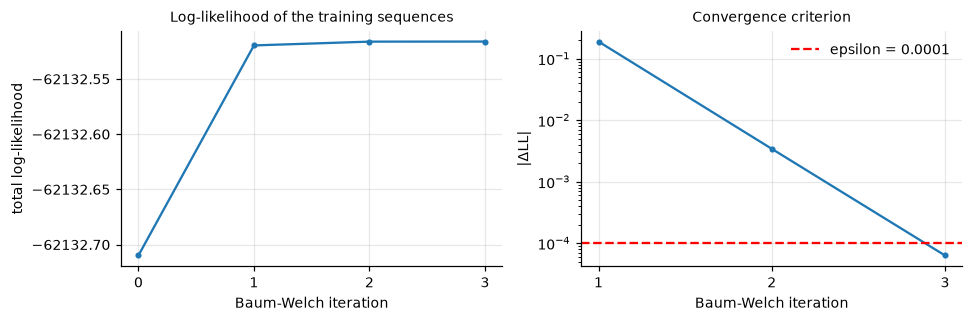

In [11]:
EPS, MAX_ITER, N_SEQ = 1e-4, 500, 10
seq_X, seq_y = build_sequences(train_clips, N_SEQ, SEED)
print(f"{N_SEQ} training sequences, each a random concatenation of the {len(train_clips)} training clips "
      f"({len(seq_X[0])} windows); first sequence order starts:",
      [train_clips[i]['name'] for i in np.random.default_rng(SEED).permutation(len(train_clips))[:6]], "...")
PI0 = expected_pi(train_clips)
print("pi fixed at the share of training clips per activity:", dict(zip(ACTIVITIES, PI0.round(3))))
params_init = init_from_labels(seq_X, seq_y, VAR_FLOOR, given_pi=PI0)
params_bw, ll_hist, converged = baum_welch(seq_X, params_init, VAR_FLOOR, eps=EPS, max_iter=MAX_ITER, update_pi=False)
n_iter = len(ll_hist) - 1
print(f"Baum-Welch: {'CONVERGED' if converged else 'DID NOT CONVERGE (hit max_iter)'} after {n_iter} iterations "
      f"(|dLL| = {abs(ll_hist[-1] - ll_hist[-2]):.2e} < eps = {EPS:g}) ; total train LL {ll_hist[0]:.2f} -> {ll_hist[-1]:.2f}")
print("smallest LL change between iterations (>= 0 means monotone):", f"{np.diff(ll_hist).min():.3e}")
ytr_ = np.concatenate([c["y"] for c in train_clips])
raw_var = np.stack([Ztr[ytr_ == k].var(0) for k in range(K)])                 # un-floored within-class variances (z-units)
PINNED = float((params_bw["var"] <= VAR_FLOOR + 1e-12).mean())
print(f"floor diagnostic (training data only): median un-floored within-class variance = {np.median(raw_var):.3f} z-units^2, "
      f"floor = {VAR_FLOOR}; {PINNED:.1%} of the 4 x {D} state variances sit exactly at the floor after Baum-Welch")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(ll_hist, marker="o", ms=3); ax[0].set_xlabel("Baum-Welch iteration"); ax[0].set_ylabel("total log-likelihood")
ax[0].set_title("Log-likelihood of the training sequences", fontsize=9)
ax[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax[0].ticklabel_format(axis="y", useOffset=False, style="plain")
d = np.abs(np.diff(ll_hist)); ax[1].semilogy(np.arange(1, len(d) + 1), np.maximum(d, 1e-12), marker="o", ms=3)
ax[1].axhline(EPS, color="r", ls="--", label=f"epsilon = {EPS:g}"); ax[1].legend(frameon=False)
ax[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax[1].set_xlabel("Baum-Welch iteration"); ax[1].set_ylabel("|ΔLL|"); ax[1].set_title("Convergence criterion", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "fig03_loglik_convergence.png", dpi=150, bbox_inches="tight"); plt.show()

**State-to-activity mapping.** Baum-Welch is unsupervised, so I verify the states still mean what they were initialized as: decode every training clip, cross-tabulate state vs true activity, and use the best one-to-one assignment (identity expected).

In [12]:
def best_mapping(params, files):
    '''Permutation state->activity that maximizes agreement between decoded states and true labels.'''
    C = np.zeros((K, K), dtype=int)
    for f in files:
        path, _ = decode(params, f["Z"]); np.add.at(C, (path, f["y"]), 1)
    perm = max(itertools.permutations(range(K)), key=lambda p: sum(C[s, p[s]] for s in range(K)))
    return np.array(perm), C

MAP_BW, C_bw = best_mapping(params_bw, train_clips)
MAP_INIT, C_init = best_mapping(params_init, train_clips)
print("state -> activity after Baum-Welch:", {ACTIVITIES[s]: ACTIVITIES[a] for s, a in enumerate(MAP_BW)})
print("state -> activity (initial model)  :", {ACTIVITIES[s]: ACTIVITIES[a] for s, a in enumerate(MAP_INIT)})

state -> activity after Baum-Welch: {'standing': 'standing', 'walking': 'walking', 'jumping': 'jumping', 'still': 'still'}
state -> activity (initial model)  : {'standing': 'standing', 'walking': 'walking', 'jumping': 'jumping', 'still': 'still'}


## 8. Evaluation on the unseen test recordings

The test clips are the hand-named recordings from separate sessions; none is used for normalization statistics, model
initialization, Baum-Welch, or the variance-floor choice. I **assert** that no test clip shares a name or a source zip with
the training set. Each test clip is decoded on its own (Viterbi) and the window decisions are pooled; a second experiment
decodes **one concatenated test sequence** in shuffled order, which is closer to a continuous stream with real activity switches.

In [13]:
tr_names, te_names = {c["name"] for c in train_clips}, {c["name"] for c in test_clips}
src = manifest.set_index(["split", "new_name"]).original_zip
tr_src = {src["train", n] for n in tr_names}; te_src = {src["test", n] for n in te_names}
assert tr_names.isdisjoint(te_names) and tr_src.isdisjoint(te_src), "LEAK: test file also in train"
print(f"OK - {len(te_names)} test clips, {len(tr_names)} train clips, no overlap in names or source zips.")
print("test clips:", sorted(te_names))

OK - 10 test clips, 33 train clips, no overlap in names or source zips.
test clips: ['jumping_10.csv', 'jumping_11.csv', 'standing_01.csv', 'standing_10.csv', 'still_01.csv', 'still_08.csv', 'still_09.csv', 'walking_01.csv', 'walking_12.csv', 'walking_13.csv']


In [14]:
def confusion(y_true, y_pred):
    cm = np.zeros((K, K), dtype=int); np.add.at(cm, (y_true, y_pred), 1); return cm

def class_metrics(cm):
    rows = []
    for k, a in enumerate(ACTIVITIES):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = cm.sum() - TP - FN - FP
        rows.append({"Activity": a, "Number of Samples": int(cm[k].sum()),
                     "Sensitivity": TP / (TP + FN) if TP + FN else np.nan,
                     "Specificity": TN / (TN + FP) if TN + FP else np.nan,
                     "Accuracy (one-vs-rest)": (TP + TN) / cm.sum()})
    return pd.DataFrame(rows)

def predict_files(params, mapping, files, use_transitions=True):
    out = []
    for f in files:
        path, logB = decode(params, f["Z"])
        s = path if use_transitions else logB.argmax(1)
        out.append(mapping[s])
    return out

def pooled(files, preds):
    return np.concatenate([f["y"] for f in files]), np.concatenate(preds)

# primary model: supervised init + Baum-Welch, Viterbi decoding, per-clip
pred_bw = predict_files(params_bw, MAP_BW, test_clips)
y_true, y_pred = pooled(test_clips, pred_bw)
CM = confusion(y_true, y_pred)
tab = class_metrics(CM)
overall = np.trace(CM) / CM.sum()
display(tab.round(3))
print(f"Overall accuracy (all {CM.sum()} test windows, per-clip Viterbi): {overall:.4f}")

per_file = pd.DataFrame([dict(clip=f["name"], true=f["activity"], windows=len(f["y"]),
                              correct=int((p == f["y"]).sum()),
                              accuracy=round(float((p == f["y"]).mean()), 3),
                              decoded=", ".join(f"{ACTIVITIES[k]}:{int((p == k).sum())}" for k in range(K) if (p == k).any()),
                              qc_note="; ".join(n for n in f["notes"].split("; ") if n.startswith("QC:")))
                         for f, p in zip(test_clips, pred_bw)])
display(per_file)

,Activity,Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,standing,13,1.000,0.933,0.948
1,walking,20,0.900,1.000,0.966
2,jumping,8,1.000,0.960,0.966
3,still,17,0.824,1.000,0.948


Overall accuracy (all 58 test windows, per-clip Viterbi): 0.9138


,clip,true,windows,correct,accuracy,decoded,qc_note
0,jumping_10.csv,jumping,4,4,1.000,jumping:4,
1,jumping_11.csv,jumping,4,4,1.000,jumping:4,
2,standing_01.csv,standing,6,6,1.000,standing:6,
3,standing_10.csv,standing,7,7,1.000,standing:7,
4,still_01.csv,still,9,8,0.889,"standing:1, still:8",QC: std-profile closer to 'standing'; QC: resi...
5,still_08.csv,still,4,2,0.500,"standing:2, still:2",QC: std-profile closer to 'standing'; QC: resi...
6,still_09.csv,still,4,4,1.000,still:4,
7,walking_01.csv,walking,9,9,1.000,walking:9,
8,walking_12.csv,walking,4,4,1.000,walking:4,
9,walking_13.csv,walking,7,5,0.714,"walking:5, jumping:2",


In [15]:
# comparison: what does Baum-Welch / the transition matrix add?
rows = []
def concat_eval(params, mapping, order, use_transitions=True):
    X = np.concatenate([test_clips[i]["Z"] for i in order]); y = np.concatenate([test_clips[i]["y"] for i in order])
    path, logB = decode(params, X)
    s = path if use_transitions else logB.argmax(1)
    return y, mapping[s]

ORDER = np.random.default_rng(SEED + 1).permutation(len(test_clips))        # fixed shuffled order of the test clips
for name, prm, mp, tr in [("Viterbi, supervised init + Baum-Welch  [primary]", params_bw, MAP_BW, True),
                          ("Viterbi, supervised init only (no Baum-Welch)", params_init, MAP_INIT, True),
                          ("Emission only (per-window argmax, no transitions)", params_bw, MAP_BW, False)]:
    yt, yp = pooled(test_clips, predict_files(prm, mp, test_clips, tr))
    yc, ypc = concat_eval(prm, mp, ORDER, tr)
    rows.append({"model": name, "per-clip accuracy": np.mean(yt == yp), "concatenated-sequence accuracy": np.mean(yc == ypc)})
cmp_tab = pd.DataFrame(rows); display(cmp_tab.round(4))

y_cat, p_cat = concat_eval(params_bw, MAP_BW, ORDER)
CM_cat = confusion(y_cat, p_cat)
print("concatenated test order:", [test_clips[i]["name"] for i in ORDER])
print(f"concatenated sequence ({len(y_cat)} windows) overall accuracy: {np.trace(CM_cat) / CM_cat.sum():.4f}")
display(class_metrics(CM_cat).round(3))

,model,per-clip accuracy,concatenated-sequence accuracy
0,"Viterbi, supervised init + Baum-Welch [primary]",0.9138,0.9138
1,"Viterbi, supervised init only (no Baum-Welch)",0.9138,0.9138
2,"Emission only (per-window argmax, no transitions)",0.8621,0.8621


concatenated test order: ['standing_01.csv', 'walking_12.csv', 'walking_13.csv', 'still_08.csv', 'walking_01.csv', 'jumping_11.csv', 'still_01.csv', 'still_09.csv', 'jumping_10.csv', 'standing_10.csv']
concatenated sequence (58 windows) overall accuracy: 0.9138


,Activity,Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,standing,13,1.000,0.933,0.948
1,walking,20,0.900,1.000,0.966
2,jumping,8,1.000,0.960,0.966
3,still,17,0.824,1.000,0.948


### 8.1 Confusion matrix (test data)

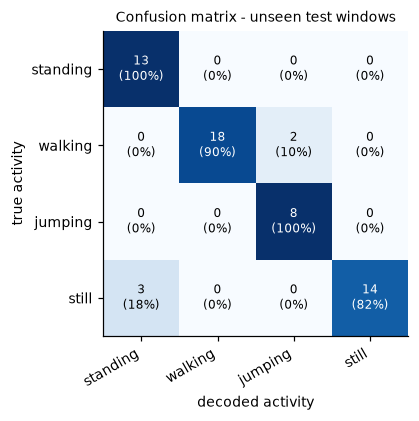

In [16]:
def heatmap(ax, M, labels, fmt, title, vmax=None, cmap="Blues", xlabel="", ylabel=""):
    im = ax.imshow(M, cmap=cmap, vmin=0, vmax=vmax if vmax is not None else M.max())
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha="right"); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt(i, j), ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.55 * (vmax or M.max()) else "black")
    ax.set_title(title, fontsize=9); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(False)

fig, ax = plt.subplots(figsize=(4.6, 3.9))
rowpct = CM / CM.sum(1, keepdims=True)
heatmap(ax, rowpct, ACTIVITIES, lambda i, j: f"{CM[i, j]}\n({rowpct[i, j] * 100:.0f}%)", "Confusion matrix - unseen test windows", vmax=1,
        xlabel="decoded activity", ylabel="true activity")
fig.tight_layout(); fig.savefig(FIG / "fig04_confusion_matrix_test.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.2 Transition matrix

Initial transition matrix (supervised, before Baum-Welch):


,standing,walking,jumping,still
standing,0.831,0.049,0.063,0.057
walking,0.046,0.873,0.044,0.036
jumping,0.042,0.054,0.875,0.028
still,0.059,0.066,0.055,0.820


Transition matrix after Baum-Welch:


,standing,walking,jumping,still
standing,0.831,0.049,0.062,0.057
walking,0.046,0.873,0.045,0.036
jumping,0.042,0.054,0.875,0.028
still,0.059,0.066,0.055,0.820


initial distribution pi: {'standing': np.float64(0.242), 'walking': np.float64(0.303), 'jumping': np.float64(0.273), 'still': np.float64(0.182)}
expected dwell time (windows, 1 window = 1 s hop): {'standing': np.float64(5.9), 'walking': np.float64(7.9), 'jumping': np.float64(8.0), 'still': np.float64(5.6)}


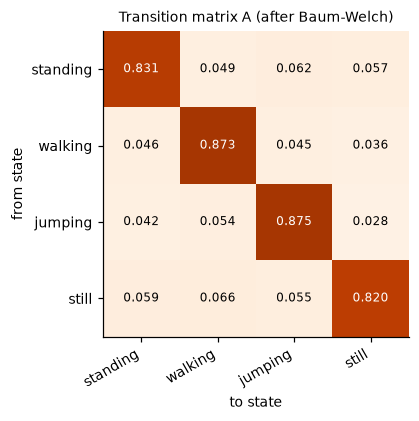

In [17]:
A_bw = params_bw["A"]
print("Initial transition matrix (supervised, before Baum-Welch):"); display(pd.DataFrame(params_init["A"], index=ACTIVITIES, columns=ACTIVITIES).round(3))
print("Transition matrix after Baum-Welch:"); display(pd.DataFrame(A_bw, index=ACTIVITIES, columns=ACTIVITIES).round(3))
print("initial distribution pi:", dict(zip(ACTIVITIES, params_bw["pi"].round(3))))
print("expected dwell time (windows, 1 window = 1 s hop):", dict(zip(ACTIVITIES, (1 / (1 - np.diag(A_bw))).round(1))))
fig, ax = plt.subplots(figsize=(4.6, 3.9))
heatmap(ax, A_bw, ACTIVITIES, lambda i, j: f"{A_bw[i, j]:.3f}", "Transition matrix A (after Baum-Welch)", vmax=1, cmap="Oranges",
        xlabel="to state", ylabel="from state")
fig.tight_layout(); fig.savefig(FIG / "fig05_transition_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.3 Emission probabilities

Most discriminative features (Fisher ratio, training data):


,Fisher ratio
acc_sma,74.32
acc_rms_z,71.97
acc_std_z,67.79
acc_energy_z,56.39
gyro_std_y,37.15
acc_std_y,36.17
gyro_sma,35.09
gyro_rms_y,34.78
acc_rms_y,34.34
gyro_energy_y,29.72


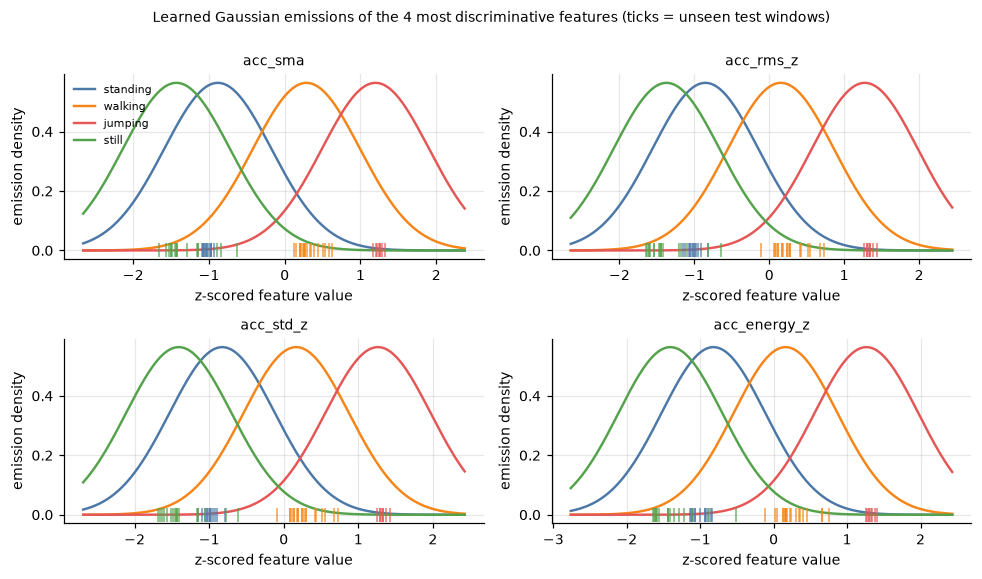

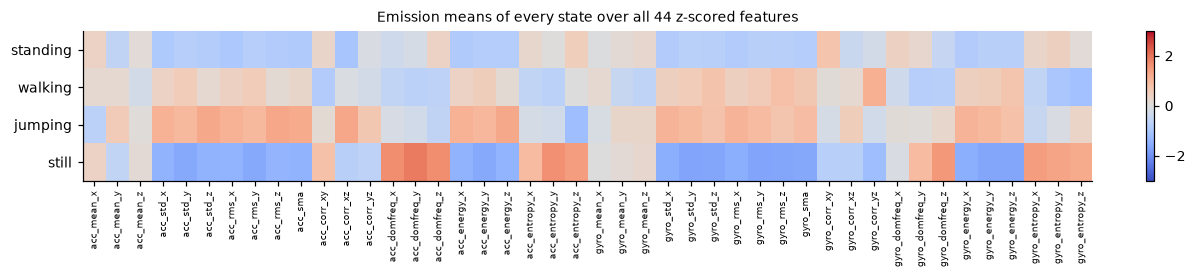

In [18]:
# Fisher score on TRAIN windows: between-class variance / within-class variance of each z-scored feature
ytr = np.concatenate([c["y"] for c in train_clips])
gm = Ztr.mean(0)
between = sum((ytr == k).sum() * (Ztr[ytr == k].mean(0) - gm) ** 2 for k in range(K))
within = sum((ytr == k).sum() * Ztr[ytr == k].var(0) for k in range(K))
fisher = pd.Series(between / (within + 1e-9), index=FEATURE_NAMES).sort_values(ascending=False)
print("Most discriminative features (Fisher ratio, training data):"); display(fisher.head(10).round(2).to_frame("Fisher ratio"))
top4 = list(fisher.index[:4])

fig, axes = plt.subplots(2, 2, figsize=(9, 5.2))
for ax, fn in zip(axes.ravel(), top4):
    d = FEATURE_NAMES.index(fn)
    lo, hi = min(Ztr[:, d].min(), Zte[:, d].min()) - 1, max(Ztr[:, d].max(), Zte[:, d].max()) + 1
    x = np.linspace(lo, hi, 400)
    for s in range(K):                       # state s is plotted under the activity it decodes to
        a = ACTIVITIES[MAP_BW[s]]; m, v = params_bw["mu"][s, d], params_bw["var"][s, d]
        ax.plot(x, np.exp(-(x - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v), color=COLORS[a], label=a, lw=1.6)
    for c in test_clips:
        ax.plot(c["Z"][:, d], np.zeros(len(c["Z"])), "|", color=COLORS[c["activity"]], ms=9, alpha=.8, clip_on=False)
    ax.set_title(fn, fontsize=9); ax.set_xlabel("z-scored feature value"); ax.set_ylabel("emission density")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Learned Gaussian emissions of the 4 most discriminative features (ticks = unseen test windows)", fontsize=9, y=1.0)
fig.tight_layout(); fig.savefig(FIG / "fig06_emission_gaussians.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(11, 2.6))
mu_state = params_bw["mu"][np.argsort(MAP_BW)]            # rows ordered as ACTIVITIES
im = ax.imshow(mu_state, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3); ax.grid(False)
ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES); ax.set_xticks(range(D)); ax.set_xticklabels(FEATURE_NAMES, rotation=90, fontsize=6)
ax.set_title("Emission means of every state over all 44 z-scored features", fontsize=9); fig.colorbar(im, ax=ax, fraction=.015)
fig.tight_layout(); fig.savefig(FIG / "fig08_state_means_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

Measured cadence: per-window dominant frequency (Hz, 0.5 Hz FFT resolution) of each accelerometer axis, median over all train+test windows of each activity. Descriptive only, not used for any choice.

In [19]:
dom_rows = []
for a in ACTIVITIES:
    Fa = np.concatenate([c["F_raw"] for c in clips if c["activity"] == a])
    row = {"activity": a, "windows": len(Fa)}
    for ax in "xyz":
        row[f"acc_{ax} median dominant freq (Hz)"] = float(np.median(Fa[:, FEATURE_NAMES.index(f"acc_domfreq_{ax}")]))
    row["share of acc windows with a dominant bin in 1.0-2.5 Hz"] = float(np.mean([(Fa[:, FEATURE_NAMES.index(f"acc_domfreq_{ax}")] >= 1.0) &
                                                                                   (Fa[:, FEATURE_NAMES.index(f"acc_domfreq_{ax}")] <= 2.5) for ax in "xyz"]))
    dom_rows.append(row)
dom_tab = pd.DataFrame(dom_rows); display(dom_tab.round(2)); dom_tab.to_csv(RES / "dominant_frequency_by_activity.csv", index=False)

,activity,windows,acc_x median dominant freq (Hz),acc_y median dominant freq (Hz),acc_z median dominant freq (Hz),share of acc windows with a dominant bin in 1.0-2.5 Hz
0,standing,50,2.00,2.50,4.00,0.37
1,walking,70,0.50,1.50,1.50,0.60
2,jumping,58,2.00,2.00,2.00,0.87
3,still,46,4.51,5.01,6.26,0.02


### 8.4 Decoded sequence over time

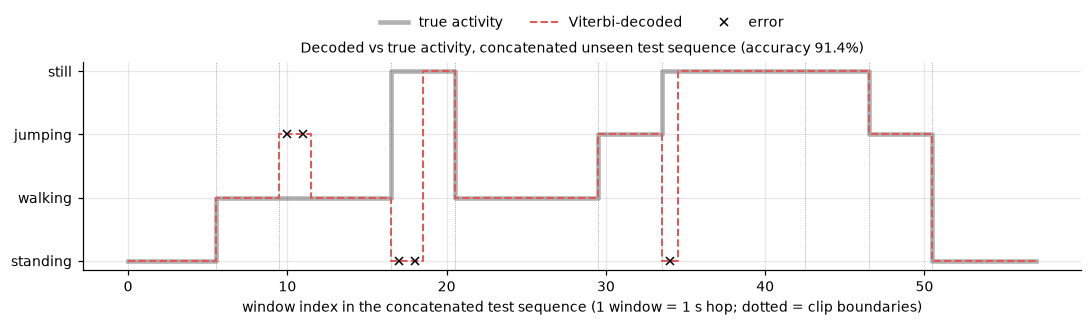

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.2))
t = np.arange(len(y_cat))
ax.step(t, y_cat, where="mid", color="#222", lw=3, alpha=.35, label="true activity")
ax.step(t, p_cat, where="mid", color="#E45756", lw=1.3, ls="--", label="Viterbi-decoded")
wrong = np.where(y_cat != p_cat)[0]; ax.plot(wrong, p_cat[wrong], "x", color="k", ms=5, label="error")
edges = np.cumsum([len(test_clips[i]["y"]) for i in ORDER])
for e in edges[:-1]: ax.axvline(e - .5, color="gray", lw=.5, ls=":")
ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES); ax.set_xlabel("window index in the concatenated test sequence (1 window = 1 s hop; dotted = clip boundaries)")
ax.set_title(f"Decoded vs true activity, concatenated unseen test sequence (accuracy {np.mean(y_cat == p_cat):.1%})", fontsize=9)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.28))
fig.tight_layout(); fig.savefig(FIG / "fig07_decoded_sequence.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.5 Post-hoc sensitivity to the variance floor (NOT used to select anything)

The floor was chosen by training-set cross-validation with a pre-declared tie-break (larger floor). Because that
cross-validation is saturated (see 7.1) the choice is weakly determined, so I show how the *test* result and Baum-Welch
behave for each candidate floor. **This table is reported for transparency only; the primary model above is not changed
by it.**

In [21]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

sens_rows = []
for fl in FLOORS:
    p0 = init_from_labels(seq_X, seq_y, fl, given_pi=PI0)
    p1, h1, cv1 = baum_welch(seq_X, p0, fl, eps=EPS, max_iter=MAX_ITER, update_pi=False)
    mp1, _ = best_mapping(p1, train_clips)
    yt1, yp1 = pooled(test_clips, predict_files(p1, mp1, test_clips))
    _, yp0 = pooled(test_clips, predict_files(p0, best_mapping(p0, train_clips)[0], test_clips))
    sens_rows.append({"var_floor": fl, "BW iterations": len(h1) - 1, "BW converged": cv1, "LL gain from BW": h1[-1] - h1[0],
                      "variances at floor": float((p1["var"] <= fl + 1e-12).mean()),
                      "test accuracy (init only)": np.mean(yt1 == yp0), "test accuracy (after BW)": np.mean(yt1 == yp1)})
sens_tab = pd.DataFrame(sens_rows); display(sens_tab.round(4))
k_ok, n_all = int(np.trace(CM)), int(CM.sum()); lo, hi = wilson(k_ok, n_all)
print(f"primary model: {k_ok}/{n_all} windows correct = {k_ok / n_all:.3f}; 95% Wilson interval {lo:.3f}-{hi:.3f} "
      f"(optimistic: overlapping windows of only {len(test_clips)} clips are not independent)")

,var_floor,BW iterations,BW converged,LL gain from BW,variances at floor,test accuracy (init only),test accuracy (after BW)
0,0.01,1,True,-0.0000,0.1250,0.9138,0.9138
1,0.05,3,True,0.0285,0.4261,0.9138,0.9138
2,0.10,4,True,26.3369,0.5625,0.8966,0.8966
3,0.25,6,True,4.0159,0.6705,0.8966,0.8966
4,0.50,3,True,0.1937,0.8011,0.9138,0.9138


primary model: 53/58 windows correct = 0.914; 95% Wilson interval 0.814-0.963 (optimistic: overlapping windows of only 10 clips are not independent)


### 8.6 Save results for the report

In [22]:
tab.to_csv(RES / "test_per_activity.csv", index=False)
pd.DataFrame(CM, index=ACTIVITIES, columns=ACTIVITIES).to_csv(RES / "test_confusion_matrix.csv")
pd.DataFrame(CM_cat, index=ACTIVITIES, columns=ACTIVITIES).to_csv(RES / "test_confusion_matrix_concatenated.csv")
pd.DataFrame(A_bw, index=ACTIVITIES, columns=ACTIVITIES).to_csv(RES / "transition_matrix.csv")
per_file.to_csv(RES / "test_per_clip.csv", index=False)
cmp_tab.to_csv(RES / "model_comparison.csv", index=False)
cv.to_csv(RES / "variance_floor_cv.csv", index=False)
fisher.head(10).to_csv(RES / "top_features_fisher.csv", header=["fisher_ratio"])
sens_tab.to_csv(RES / "variance_floor_sensitivity_posthoc.csv", index=False)
metrics = dict(
    seed=SEED, window_samples=WIN, hop_samples=HOP, n_features=D, var_floor=VAR_FLOOR, eps=EPS, max_iter=MAX_ITER, n_train_sequences=N_SEQ,
    measured_hz_mean=FS, measured_hz_min=float(hz_tab.hz.min()), measured_hz_max=float(hz_tab.hz.max()), measured_hz_std=float(hz_tab.hz.std()),
    n_train_clips=len(train_clips), n_test_clips=len(test_clips),
    n_train_windows=int(len(Ztr)), n_test_windows=int(len(Zte)),
    bw_converged=bool(converged), bw_iterations=int(n_iter), ll_first=float(ll_hist[0]), ll_final=float(ll_hist[-1]),
    ll_min_step=float(np.diff(ll_hist).min()),
    overall_accuracy_per_clip=float(overall), overall_accuracy_concatenated=float(np.trace(CM_cat) / CM_cat.sum()),
    accuracy_init_only_per_clip=float(cmp_tab.iloc[1, 1]), accuracy_emission_only_per_clip=float(cmp_tab.iloc[2, 1]),
    variances_at_floor=PINNED, median_unfloored_variance=float(np.median(raw_var)),
    overall_accuracy_wilson95=[float(lo), float(hi)], correct_windows=k_ok, test_windows=n_all,
    state_to_activity={ACTIVITIES[s]: ACTIVITIES[a] for s, a in enumerate(MAP_BW)},
    top_features=list(fisher.index[:4]),
)
(RES / "metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))

{
  "seed": 42,
  "window_samples": 200,
  "hop_samples": 100,
  "n_features": 44,
  "var_floor": 0.5,
  "eps": 0.0001,
  "max_iter": 500,
  "n_train_sequences": 10,
  "measured_hz_mean": 100.11824993446407,
  "measured_hz_min": 100.10519053421335,
  "measured_hz_max": 100.12361833021275,
  "measured_hz_std": 0.0051132089159660115,
  "n_train_clips": 33,
  "n_test_clips": 10,
  "n_train_windows": 166,
  "n_test_windows": 58,
  "bw_converged": true,
  "bw_iterations": 3,
  "ll_first": -62132.70979475938,
  "ll_final": -62132.51610472817,
  "ll_min_step": 6.339108222164214e-05,
  "overall_accuracy_per_clip": 0.9137931034482759,
  "overall_accuracy_concatenated": 0.9137931034482759,
  "accuracy_init_only_per_clip": 0.9137931034482759,
  "accuracy_emission_only_per_clip": 0.8620689655172413,
  "variances_at_floor": 0.8011363636363636,
  "median_unfloored_variance": 0.06517224830155141,
  "overall_accuracy_wilson95": [
    0.8135613862273433,
    0.9626151680662066
  ],
  "correct_windows":

## 9. Discussion

All numbers below come from the cells above (`results/` holds the same values). The test set is small (10 clips, 58 windows),
so every percentage carries a wide margin: the 95 % Wilson interval for the overall accuracy is 81.4-96.3 %, and that is
optimistic because overlapping windows from 10 clips are not independent.

### 9.1 Which activities were easiest and hardest

* **Jumping was the easiest** (8/8 windows, sensitivity 1.00). Its accelerometer-magnitude std is about 4-8, against
  roughly 0.7-1.6 for walking in the cleaned clips, and the four most discriminative training features (`acc_sma`, `acc_rms_z`, `acc_std_z`,
  `acc_energy_z`) are all amplitude features. Its dominant frequency is 2.0 Hz on all three axes (a dominant bin in the
  1.0-2.5 Hz range in 87 % of jumping windows).
* **Standing** was never missed (13/13) but it absorbed errors from still: specificity 0.933.
* **Walking** reached sensitivity 0.90 (18/20). The two errors are windows of `walking_13`, my most vigorous walking clip (accelerometer std
  1.56 against a walking median of 0.77), decoded as jumping. I did not trace which feature caused it, so the reason is **UNVERIFIED**.
* **Still was the hardest** (sensitivity 0.82, 14/17) and, as I suspected before modeling, the confusion is still vs standing. Both are phone-in-hand
  with only small body sway; their typical accelerometer std is 0.041 (still) against 0.092 (standing), a factor of about 2, so the
  margin is thin. All three errors fall in the two still clips that my QC had already flagged before any model was fit:
  `still_01` (a pick-up transient that survived the 1.5 s trim; 1 of 9 windows wrong) and `still_08` (its raw per-second std stayed elevated for the first ~4 s, so I was not fully still; 2 of 4 windows wrong).
  The third still test clip, `still_09`, was decoded perfectly. So part of this "model error" is a data-quality error in my own recordings.

### 9.2 What the transition matrix says (and does not say)

The diagonal of A is 0.82 (still) to 0.875 (jumping), i.e. an expected dwell time of 5.6-8.0 windows. But my clips are only 5-10 s long, so
**the diagonal mainly measures my clip length, not how long a person really stays in an activity.** The off-diagonal entries (0.03-0.07) are nearly
uniform because I built the training sequences from randomly shuffled clips; they reflect the shuffle, not human behavior. I therefore
**cannot claim** that, for example, still &rarr; standing &rarr; walking is more natural than still &rarr; jumping, even though real life is like that.
To learn realistic transitions I would need continuous recordings with natural switches between activities. What the HMM did add is
temporal smoothing: per-window emission-only decisions give 50/58 (86.2 %), Viterbi gives 53/58 (91.4 %), a gain of 3 windows.

### 9.3 Baum-Welch, the variance floor, and what they did to the result

Baum-Welch converged after 3 iterations (|&Delta;LL| = 6.3e-5 &lt; 1e-4) and raised the total training log-likelihood by only 0.19
(&minus;62132.71 &rarr; &minus;62132.52). The test predictions are **identical** to the supervised-initialized model without Baum-Welch.
This is expected: the activities are well separated in feature space and the clips are labeled, so the supervised estimate is already
almost a fixed point of EM. Baum-Welch is implemented and convergence-checked, but it did not improve this dataset.

The selected variance floor (0.5) is large: 80 % of the 4 x 44 state variances sit exactly at the floor, while the median
un-floored within-class variance is only 0.065. The model therefore behaves much like a nearest-mean classifier with a shared width.
The floor was chosen by training-set cross-validation (leave-one-clip-out accuracy 99.4-100 % for every candidate, so the criterion was saturated and the
pre-declared tie-break picked the largest value). The post-hoc sensitivity table (8.5) shows the test accuracy only moves between
89.7 % and 91.4 % (one window) over floors 0.01-0.5, so the conclusions do not depend on this choice.
One further honesty note: in my first run pi was estimated from the starts of 10 shuffled sequences, which gave still a pi of 0.001 by chance; I replaced it by
the share of training clips per activity (documented in section 7). That changed the test result by one window (52/58 to 53/58); I made the change because the training-side
value was an obvious sampling artifact, not to raise the score.

### 9.4 Noise, sampling rate and cadence

* **Sampling rate.** All clips were measured at 100.105-100.124 Hz (std 0.005 Hz) with 9.98-9.99 ms between every pair of samples, so the single-device
  data needed no resampling. The Nyquist frequency is 50 Hz, while the activity signal lives below about 10 Hz (walking ~1.5 Hz, jumping ~2 Hz), so 100 Hz is generous.
  I did **not** test lower rates, so I cannot say how far the rate could be reduced.
* **Noise.** Still and standing are close mainly because of sensor noise and hand tremor: the per-window dominant frequency of still (4.5-6.3 Hz median) is noise,
  not a rhythm. The 2 s window gives only 0.5 Hz frequency resolution, which is also coarse for telling a slow walking cadence from sway.
* **Slow walking cadence.** The median per-window dominant frequency of walking is 1.5 Hz on the y and z axes (0.5 Hz on x, the lower edge of the search band, probably turning/sway),
  and only 60 % of walking windows have a dominant bin in 1.0-2.5 Hz. My cadence is therefore at the low end of the textbook 1.5-2.5 Hz, consistent with slow indoor walking with turns in a living room.

### 9.5 Limitations

* **One person, one iPhone 13, one device id, one place (indoors), one day.** Nothing here shows the model works for other people, phones or placements (pocket, bag).
* **Little data.** After cleaning, each activity has less than 90 s (standing 64.0 s, walking 86.7 s, jumping 73.7 s, still 58.5 s), 33 training clips (166 windows).
* **Leave-one-clip-out accuracy on the training set (99.4-100 %) is much higher than the test accuracy (91.4 %).** The test clips come from separate sessions and contain the flagged still clips,
  so the training-set number overstates how the model behaves on new recordings.
* The 10 test clips are small in number, and a split by clip leaves only 8 windows for jumping.
* Accelerometer and gyroscope units are inferred, not documented in the files (**UNVERIFIED**).

### 9.6 Improvements

1. Record the missing data: 4 more standing, 1 more walking, 3 more jumping and 5 more still clips of 10 s (about 26, 3, 16 and 32 s short of 90 s respectively) and re-record the two flagged still clips.
2. Record continuous sessions with natural switches (still &rarr; standing &rarr; walking &rarr; jumping) and learn A from them.
3. Use a hidden semi-Markov model (explicit dwell-time distributions) instead of the geometric dwell implied by a plain HMM.
4. Add features that separate still from standing: gravity direction / orientation from the raw accelerometer, a magnetometer or barometer, and longer windows for finer frequency resolution.
5. Try full-covariance or mixture emissions (the diagonal Gaussian ignores correlation between features such as `acc_std` and `acc_rms`).
6. Evaluate across sessions, people and phone placements, and detect and trim pick-up transients automatically instead of a fixed 1.5 s cut.